# Both sheets explained simply (the "like I'm 8" version of `lab-2-in-depth.ipynb`)

Same two sheets, same numbers, but with pictures and everyday words.

| | Sheet | The question in kid words | Where |
|---|---|---|---|
| **1** | *Psychrometrics challenge* | "How much **water** hides in the air, and how much **energy** does the air carry?" | **Part A** |
| **2** | *Lab 2 (PMV/PPD)* | "Will a **person** feel comfortable in that air?" | **Part B** |

**How they connect:** sheet 1 is about the **air**, sheet 2 is about the **person standing in the air**. The water pressure $p_v$ you find in Part A is the same $p_v$ the body needs in Part B.

In [1]:
import sys; sys.path.insert(0, "../../shared")  # folder holding calculate_pmv_ppd.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from calculate_pmv_ppd import calculate_pmv_ppd

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
SUMMER, WINTER = ORANGE, BLUE      # orange = summer, blue = winter, everywhere

# Part A: Sheet 1, the air and its hidden water

## A0. Fancy words → simple words

| Fancy word | Simple meaning | Unit |
|---|---|---|
| **Moist air** | The air around us. It is **dry air + a little invisible water (water vapour)**. | - |
| **Psychrometrics** | The science of "how much water is in the air". | - |
| **Pressure** | How hard the air pushes on things. | Pa (pascal); 1 bar = 100 000 Pa |
| **Partial vapour pressure** $p_v$ | How hard the **water part alone** pushes. More water → bigger number. It tells us **how much** water is there. | Pa |
| **Saturation pressure** $p_{sat}$ | The **biggest** $p_v$ the air can have at a temperature. Like a sponge that is completely full. More water than that falls out as drops. | Pa |
| **Relative humidity** $\varphi$ | **How full the sponge is.** 60 % = 60 out of 100 spoonfuls. $\varphi = p_v / p_{sat}$ | % |
| **Humidity ratio** $x$ | **Grams of water in every kilogram of dry air.** | g/kg |
| **Dew point** $t_{dp}$ | The temperature where the air gets so cold its sponge is **full** → drops appear (like on a cold glass of lemonade). | °C |
| **Enthalpy** $h$ | **How much energy 1 kg of air carries.** Part is warmth you can feel, part is hidden in the water. | kJ/kg |
| **Sensible heat** | The warmth a thermometer can feel. | kJ/kg |
| **Latent heat** | Energy **hidden** in water vapour (it took energy to make the water into vapour). You can't feel it, but an air conditioner must remove it. | kJ/kg |
| **Ideal gas** | A gas simple enough to follow $pV = mRT$. We treat air like this. | - |
| **Specific heat** | How **stubborn** a material is about warming: the energy to warm 1 kg by 1 degree. Water is very stubborn (4.19), air is easy (1.0). | kJ/(kg·K) |
| **Condensation** | Invisible water in the air turning into **drops** of liquid (fog, dew, a wet cold glass). | - |
| **Vapour density** | How many kilograms of water vapour float in each cubic metre of air. | kg/m³ |

## A1. How much does the air in a room weigh?

Air feels like nothing, but it has weight. The room is 6 m × 4 m × 3 m, at 25 °C and normal pressure (100 000 Pa).

**Recipe** (the "ideal gas law": pressure × volume = mass × R × temperature):

$$m = \frac{p\cdot V}{R\cdot T}$$

- $p$ = 100 000 Pa, $V$ = 6·4·3 = 72 m³
- $R$ = 287 J/(kg·K) is a number for air
- $T$ = 25 + 273.15 = 298.15 K (temperature in kelvin: always add 273.15 to °C)

The room has 72 m3 of air. It weighs 84.1 kg (about 1.2 adults!). Density = 1.17 kg/m3


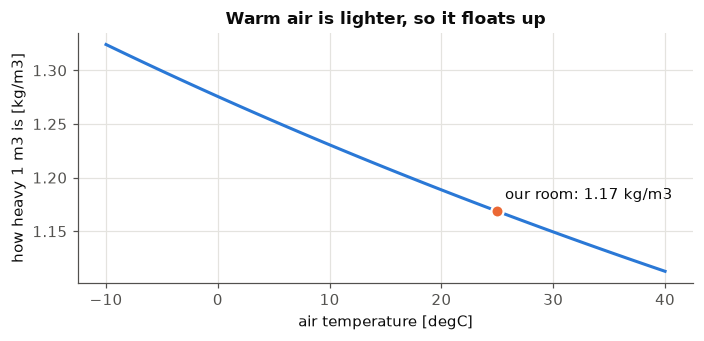

In [2]:
p, R = 1e5, 287
V = 6 * 4 * 3                       # m3
T = 25 + 273.15                     # K
m = p * V / (R * T)                 # kg of air in the room
rho = m / V                         # kg per m3 ("density" = how heavy each cubic metre is)
print(f"The room has {V} m3 of air. It weighs {m:.1f} kg (about {m/70:.1f} adults!). Density = {rho:.2f} kg/m3")

t = np.linspace(-10, 40, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t, p / (R * (t + 273.15)), color=BLUE, lw=2)
ax.plot(25, rho, "o", color=ORANGE, ms=8, mec="white", mew=1.5)
ax.annotate(f"our room: {rho:.2f} kg/m3", (25, rho), xytext=(5, 8), textcoords="offset points")
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("how heavy 1 m3 is [kg/m3]")
ax.set_title("Warm air is lighter, so it floats up")
plt.tight_layout(); plt.show()

**Reading it.** When air gets warm it spreads out, so each cubic metre holds less stuff and weighs less. That is why warm air rises (hot-air balloons!). Our room's air weighs about **84 kg**.

## A2. The sponge: warm air holds much more water

The sheet gives a table: for each temperature, the **biggest** water pressure the air can hold ($p_{sat}$). Between table rows we draw a straight line (interpolation).

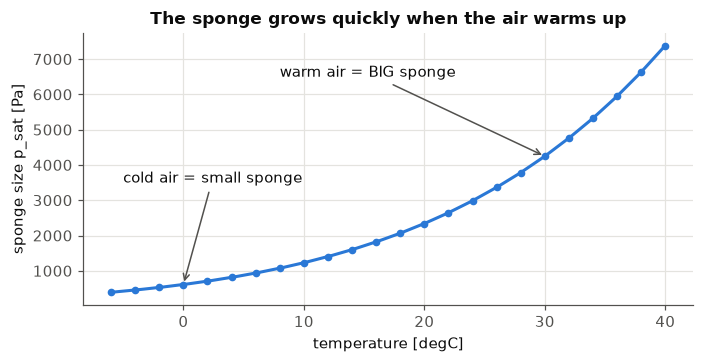

In [3]:
T_TAB = np.arange(-6, 41, 2)
P_TAB = np.array([390.9, 454.9, 527.9, 611.2, 706, 813.5, 935.3, 1073, 1228, 1403, 1599, 1819,
                  2065, 2339, 2645, 2986, 3364, 3783, 4247, 4760, 5325, 5948, 6633, 7385])

def p_sat(t):  return np.interp(t, T_TAB, P_TAB)        # biggest water pressure at temperature t [Pa]
def t_sat(pv): return np.interp(pv, P_TAB, T_TAB)       # reverse look-up: which temperature fills the sponge? (= dew point)
P_ATM = 1e5
def humidity_ratio(pv, p=P_ATM): return 0.622 * pv / (p - pv)         # kg water per kg dry air
def enthalpy(t, x):              return t + x * (2500 + 1.84 * t)      # kJ per kg dry air

tt = np.linspace(-6, 40, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(tt, p_sat(tt), color=BLUE, lw=2); ax.plot(T_TAB, P_TAB, "o", color=BLUE, ms=4)
ax.annotate("cold air = small sponge", (0, p_sat(0)), xytext=(-5, 3500), arrowprops=dict(arrowstyle="->", color=MUTED))
ax.annotate("warm air = BIG sponge", (30, p_sat(30)), xytext=(8, 6500), arrowprops=dict(arrowstyle="->", color=MUTED))
ax.set_xlabel("temperature [degC]"); ax.set_ylabel("sponge size p_sat [Pa]")
ax.set_title("The sponge grows quickly when the air warms up")
plt.tight_layout(); plt.show()

**Reading it.** At 0 °C the air can hold 611 Pa of water, at 30 °C it can hold 4247 Pa, which is about **7 times more**. Remember this picture; everything else in Part A comes from it.

## A3. Summer day vs winter day (the 5 steps of the sheet)

**Summer:** 30 °C and 60 % humidity. **Winter:** 0 °C and 85 % humidity. Both at 1 bar.

1. **Sponge size** $p_{sat}$: look it up in the table.
2. **How much water is really there:** $p_v = \varphi \cdot p_{sat}$ (60 % of the sponge).
3. **Grams of water per kg of dry air:** $x = 0.622\,\dfrac{p_v}{p - p_v}$ (0.622 because water molecules are lighter than air molecules).
4. **Dew point:** find the temperature whose sponge size equals $p_v$ (look the table up **backwards**).
5. **Energy carried:** $h = t + x\,(2500 + 1.84\,t)$ (warmth + hidden energy; 2500 kJ/kg is what it costs to turn 1 kg of water into vapour).

In [4]:
cases = {"Summer day": (30, 0.60), "Winter day": (0, 0.85)}
rows = {}
for name, (t, phi) in cases.items():
    ps = p_sat(t); pv = phi * ps; x = humidity_ratio(pv); tdp = t_sat(pv); h = enthalpy(t, x)
    rows[name] = {"t [degC]": t, "humidity [%]": phi * 100, "1. p_sat [Pa]": round(float(ps), 1),
                  "2. p_v [Pa]": round(float(pv), 1), "3. x [g/kg]": round(1000 * x, 2),
                  "4. dew point [degC]": round(float(tdp), 2), "5. h [kJ/kg]": round(h, 2)}
pd.DataFrame(rows)

,Summer day,Winter day
t [degC],30.00,0.00
humidity [%],60.00,85.00
1. p_sat [Pa],4247.00,611.20
2. p_v [Pa],2548.20,519.50
3. x [g/kg],16.26,3.25
4. dew point [degC],21.37,-2.23
5. h [kJ/kg],71.56,8.12


**By hand, summer:** $p_v = 0.60\cdot4247 = 2548.2$ Pa → $x = 0.622\cdot\dfrac{2548.2}{100000-2548.2} = 0.01626$ kg/kg = **16.26 g/kg** → $h = 30 + 0.01626\,(2500+55.2) = $ **71.56 kJ/kg**.
**Winter:** $p_v = 0.85\cdot611.2 = 519.5$ Pa → $x = $ **3.25 g/kg** → $h = $ **8.12 kJ/kg**.

(If you want these cross-checked against the in-depth notebook: they are the same numbers.)

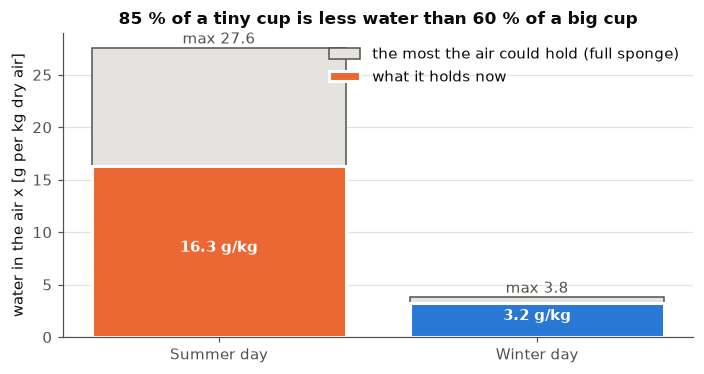

In [5]:
# how much water is in the air (cup filled) vs how much the air COULD hold (the cup's size)
names = list(cases)
now = [1000 * humidity_ratio(phi * p_sat(t)) for t, phi in cases.values()]
cap = [1000 * humidity_ratio(p_sat(t)) for t, phi in cases.values()]
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(names, cap, color="#e4e3df", edgecolor=MUTED, label="the most the air could hold (full sponge)")
ax.bar(names, now, color=[SUMMER, WINTER], edgecolor="white", linewidth=2, label="what it holds now")
for i in range(2):
    ax.text(i, now[i] / 2, f"{now[i]:.1f} g/kg", ha="center", color="white", fontweight="bold")
    ax.text(i, cap[i] + 0.4, f"max {cap[i]:.1f}", ha="center", color=MUTED)
ax.set_ylabel("water in the air x [g per kg dry air]"); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("85 % of a tiny cup is less water than 60 % of a big cup")
plt.tight_layout(); plt.show()

**Reading it.** Winter feels "85 % wet", but the cup is tiny, so there are only **3.2 g** of water per kg of air. Summer is "only 60 %" but the cup is huge, so there are **16.3 g**, five times more. **Lesson: the percentage alone lies; the grams tell the truth.**

## Why do we measure water in the air with *pressure* and not in kilograms?

**We use both! They are the same thing said in two ways.**

Imagine a box of tiny bouncing balls (the water molecules). The more balls, the harder they bump the walls of the box. **That bumping is the pressure.** So *more pressure = more water*. Pressure is just a way to count the water without a scale.

The formula that links the two is $p_v = \rho_v \cdot R_v \cdot T$: pressure = (kg of vapour in each m³) × a fixed number × the temperature. And the **humidity ratio** $x$ is just "kg of water ÷ kg of dry air", exactly the number you described:

$$x = \frac{m_{vapour}}{m_{dry\ air}} = 0.622\,\frac{p_v}{p - p_v}$$

**Why use pressure at all?**
- The "sponge is full" rule is written in pressure: the air is full when $p_v = p_{sat}$, so a look-up table does the job. Relative humidity is simply $p_v / p_{sat}$.
- The dew point is also found with that table.

**Why also use kilograms ($x$)?**
- $x$ **does not change** when you only warm up or cool down the air. The water is still the same water! That makes it the honest number for energy and for "how much water do we need to add or remove".
- The percentage (relative humidity) *does* change when you warm the air, as you can see below.

In [6]:
R_a, R_v = 287.0, 461.5            # gas constants [J/(kg.K)]: dry air, water vapour (R_a/R_v = 0.622)
t, phi = 30, 0.60
T = t + 273.15                     # K
pv = phi * p_sat(t)                # Pa, vapour partial pressure
pa = 1e5 - pv                      # Pa, dry-air partial pressure (Dalton: p = pa + pv)
rho_v = pv / (R_v * T)             # kg of vapour per m3   (from pv = rho_v * R_v * T)
rho_a = pa / (R_a * T)             # kg of dry air per m3  (from pa = rho_a * R_a * T)
print(f"vapour : {rho_v*1000:.2f} g per m3     dry air: {rho_a:.3f} kg per m3")
print(f"x = rho_v/rho_a = {1000*rho_v/rho_a:.2f} g/kg      formula 0.622*pv/(p-pv) = {1000*humidity_ratio(pv):.2f} g/kg   (same thing)")

# heat the SAME air (nothing added, nothing removed, total pressure fixed at 1 bar)
rows = []
for tt_ in (25, 30, 35, 40):
    rows.append({"t [degC]": tt_, "x [g/kg]": round(1000 * humidity_ratio(pv), 2), "p_v [Pa]": round(pv, 1),
                 "vapour [g/m3]": round(1000 * pv / (R_v * (tt_ + 273.15)), 2),
                 "p_sat [Pa]": round(float(p_sat(tt_)), 0), "relative humidity [%]": round(100 * pv / float(p_sat(tt_)))})
pd.DataFrame(rows)

vapour : 18.21 g per m3     dry air: 1.120 kg per m3
x = rho_v/rho_a = 16.26 g/kg      formula 0.622*pv/(p-pv) = 16.26 g/kg   (same thing)


,t [degC],x [g/kg],p_v [Pa],vapour [g/m3],p_sat [Pa],relative humidity [%]
0,25,16.26,2548.2,18.52,3175.0,80
1,30,16.26,2548.2,18.21,4247.0,60
2,35,16.26,2548.2,17.92,5636.0,45
3,40,16.26,2548.2,17.63,7385.0,35


**Reading it.** While we warm the same air, the water in it ($x$ in g/kg and $p_v$ in Pa) **stays the same**. But the percentage falls from 80 % (at 25 °C) to 35 % (at 40 °C), because warm air has a bigger sponge. So the percentage is a bit of a trickster; grams per kg (and pressure) tell the truth.

## A4. Dew point: when the sponge gets full

Imagine the air in the summer day getting cooled down **without adding or removing water**. The amount of water stays the same, but the sponge gets smaller. At some temperature the sponge is exactly full. That is the **dew point**. Cooler than that, water drops out (fog, dew, a wet cold glass).

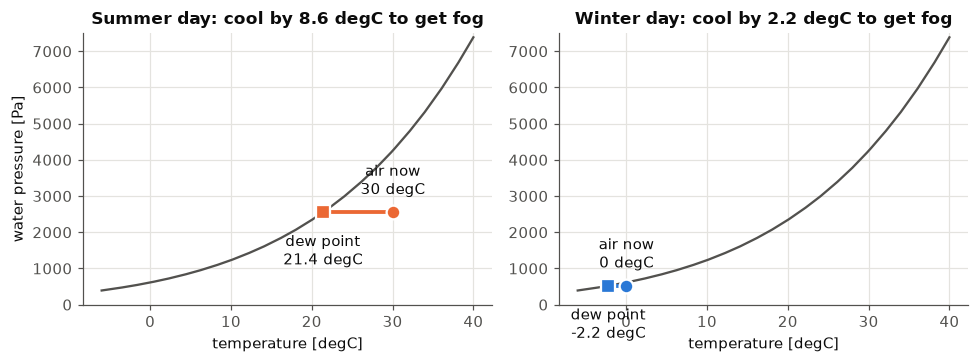

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, (name, (t, phi)), col in zip(axs, cases.items(), [SUMMER, WINTER]):
    pv = phi * p_sat(t); tdp = float(t_sat(pv))
    ax.plot(tt, p_sat(tt), color=MUTED, lw=1.5)
    ax.hlines(pv, tdp, t, color=col, lw=2.5)
    ax.plot(t, pv, "o", color=col, ms=9, mec="white", mew=1.5); ax.plot(tdp, pv, "s", color=col, ms=9, mec="white", mew=1.5)
    ax.annotate(f"air now\n{t} degC", (t, pv), xytext=(0, 12), textcoords="offset points", ha="center")
    ax.annotate(f"dew point\n{tdp:.1f} degC", (tdp, pv), xytext=(0, -34), textcoords="offset points", ha="center")
    ax.set_title(f"{name}: cool by {t - tdp:.1f} degC to get fog"); ax.set_xlabel("temperature [degC]"); ax.set_ylim(0, 7500)
axs[0].set_ylabel("water pressure [Pa]")
plt.tight_layout(); plt.show()

**Reading it.** Circle = the air now. Square = its dew point. The line is the cooling. In summer the air only needs to cool **8.6 °C** (to 21.4 °C) before drops form, so a cold wall or an air-conditioner pipe at 15 °C will **drip**. In winter, 2.2 °C below zero is enough, so you get frost on a cold window.

## What is condensation?

**Condensation is when invisible water in the air turns into tiny drops of liquid water.**

You have seen it:
- the drops on the **outside of a cold glass** of lemonade,
- the **mirror fogging up** after a hot shower,
- **dew** on the grass in the morning, **fog** and **clouds**,
- water on a **window** on a cold day.

**Why it happens:** remember the sponge. Cold air has a *small* sponge. If air touches something cold, its sponge shrinks until it can't hold all its water any more. The extra water **squeezes out as drops**. The temperature where this starts is the **dew point**.

- Surface **warmer** than the dew point → stays dry.
- Surface **colder** than the dew point → drops appear.

When water turns from vapour into liquid it **gives out heat** (the hidden energy from before). An air conditioner works like a cold glass: it makes water drip out of the air, which both cools **and dries** the room.

At 15 degC the air can hold only 10.81 g/kg, it carries 16.26 g/kg
-> 5.45 g of every kg turns to liquid; for the room's 84.14 kg of air that is 459 g of water
-> condensing releases 13.6 kJ per kg of air, 1146 kJ in the room


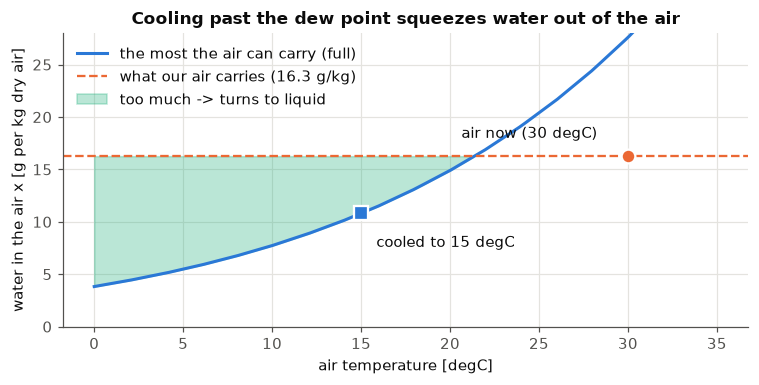

In [8]:
t0, phi0, t_end = 30, 0.60, 15
x_now = 1000 * humidity_ratio(phi0 * p_sat(t0))          # g/kg, what the air carries
x_end = 1000 * humidity_ratio(p_sat(t_end))              # g/kg, the most air at 15 degC can carry
drop = x_now - x_end                                     # g of liquid per kg of dry air
room_air = 84.14                                         # kg, the air mass of the 6x4x3 m room (A1)
print(f"At {t_end} degC the air can hold only {x_end:.2f} g/kg, it carries {x_now:.2f} g/kg")
print(f"-> {drop:.2f} g of every kg turns to liquid; for the room's {room_air} kg of air that is {drop*room_air:.0f} g of water")
print(f"-> condensing releases {drop/1000*2500:.1f} kJ per kg of air, {drop/1000*2500*room_air:.0f} kJ in the room")

tt2 = np.linspace(0, 35, 200)
x_sat = 1000 * humidity_ratio(p_sat(tt2))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(tt2, x_sat, color=BLUE, lw=2, label="the most the air can carry (full)")
ax.axhline(x_now, color=ORANGE, ls="--", lw=1.5, label=f"what our air carries ({x_now:.1f} g/kg)")
ax.fill_between(tt2, x_sat, x_now, where=x_sat < x_now, color=AQUA, alpha=0.3, label="too much -> turns to liquid")
ax.plot(t0, x_now, "o", color=ORANGE, ms=9, mec="white", mew=1.5); ax.annotate("air now (30 degC)", (t0, x_now), xytext=(-20, 12), textcoords="offset points", ha="right")
ax.plot(t_end, x_end, "s", color=BLUE, ms=9, mec="white", mew=1.5); ax.annotate(f"cooled to {t_end} degC", (t_end, x_end), xytext=(10, -22), textcoords="offset points")
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("water in the air x [g per kg dry air]"); ax.set_ylim(0, 28)
ax.legend(frameon=False, loc="upper left"); ax.set_title("Cooling past the dew point squeezes water out of the air")
plt.tight_layout(); plt.show()

**Reading it.** Summer air (30 °C, 60 %) has a dew point of 21.4 °C. If it touches something at 15 °C, its sponge only holds 10.8 g per kg instead of 16.3 g, so about 5.5 g per kg turns into drops. For all the air in the room that is about **half a litre of water**, a small bottle! The green area on the chart is the water that has to leave the air.

## What is specific heat?

**Specific heat tells you how "stubborn" a material is about getting warm.**

It is the energy needed to warm **1 kg** of something by **1 degree**. Think of two pots on a stove: one with a little oil and one with the same weight of water. The oil gets hot much faster. Water is "stubborn": it needs a lot of energy for every degree, so it also stays warm for a long time.

$$\text{energy} = \text{mass}\times\text{specific heat}\times\text{temperature change}$$

| Material | Specific heat (kJ per kg per degree) | In kid words |
|---|---|---|
| Dry air | **1.0** (exactly 1.006) | warms up easily |
| Water vapour | **1.84** | in between |
| Liquid water | **4.19** | very stubborn |

**Where do we use it?** In the **energy of the air** $h$:

$$h = \underbrace{1\cdot t}_{\text{warmth of the dry air}} + x\Big(\underbrace{2500}_{\text{energy to make vapour}} + \underbrace{1.84\cdot t}_{\text{warmth of the vapour}}\Big)$$

The "1" is the specific heat of dry air, the "1.84" the specific heat of vapour. The 2500 is **not** a specific heat: it is the big chunk of energy needed to turn 1 kg of liquid water into vapour (even without getting any warmer).

In [9]:
c_pa, c_pv, c_w = 1.006, 1.84, 4.19                  # specific heats [kJ/(kg.K)]: dry air, vapour, liquid water
m_room = 84.14                                       # kg of air in the 6x4x3 m room
print(f"warm the room's air by 1 K : {m_room*c_pa:6.1f} kJ")
print(f"warm the same MASS of water: {m_room*c_w:6.1f} kJ   ({c_w/c_pa:.1f} times more)")

x = humidity_ratio(0.60 * p_sat(30)); t = 30          # summer day
air_part = t                                          # sheet: c_pa taken as 1 -> 1*t
vap_part = x * 1.84 * t                               # sensible heat of the vapour
latent = x * 2500                                     # evaporation energy
print(f"h = {air_part:.2f} (dry air) + {vap_part:.2f} (vapour warmth) + {latent:.2f} (latent) = {air_part+vap_part+latent:.2f} kJ/kg")
print(f"with c_pa = 1.006 instead of 1: h = {c_pa*t+vap_part+latent:.2f} kJ/kg (difference {100*(c_pa-1)*t/(air_part+vap_part+latent):.2f} %)")

warm the room's air by 1 K :   84.6 kJ
warm the same MASS of water:  352.5 kJ   (4.2 times more)
h = 30.00 (dry air) + 0.90 (vapour warmth) + 40.66 (latent) = 71.56 kJ/kg
with c_pa = 1.006 instead of 1: h = 71.74 kJ/kg (difference 0.25 %)


**Reading it.** Warming the air in the room by one degree takes about 85 kJ, but warming the same weight of water takes more than 350 kJ, about 4 times more. In the summer air's 71.6 kJ/kg: 30 is the warmth of the dry air, 0.9 the warmth of the water vapour and 40.7 the hidden energy. Using 1.006 instead of 1 changes the answer by a tiny 0.25 %, so the sheet just uses 1.

## A5. Enthalpy: the energy you can't feel

$h = \underbrace{t}_{\text{warmth (sensible)}} + \underbrace{x\,(2500 + 1.84\,t)}_{\text{hidden in water (latent)}}$

Think of **two piggy banks**: one holds the warmth you can feel with a thermometer, the other holds energy hidden in the water. An air conditioner has to empty **both**.

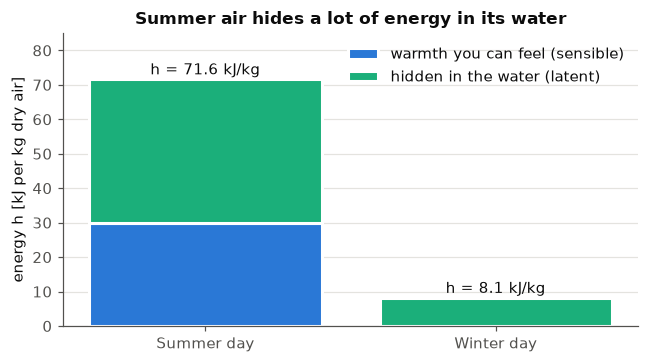

In [10]:
sens = [t for t, phi in cases.values()]
lat = [humidity_ratio(phi * p_sat(t)) * (2500 + 1.84 * t) for t, phi in cases.values()]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(names, sens, color=BLUE, edgecolor="white", linewidth=2, label="warmth you can feel (sensible)")
ax.bar(names, lat, bottom=sens, color=AQUA, edgecolor="white", linewidth=2, label="hidden in the water (latent)")
for i in range(2): ax.text(i, sens[i] + lat[i] + 1.5, f"h = {sens[i] + lat[i]:.1f} kJ/kg", ha="center")
ax.set_ylabel("energy h [kJ per kg dry air]"); ax.set_ylim(0, 85); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("Summer air hides a lot of energy in its water")
plt.tight_layout(); plt.show()

**Reading it.** In summer, 42 of the 71.6 kJ/kg are hidden in the water, so cooling alone is not enough: you must also **dry** the air. In winter (0 °C) there is no warmth to count, so the whole 8.1 kJ/kg is hidden energy.

## A6. The whole day

The sheet gives 24 hourly temperatures and humidities (Bucharest, 8 August and 1 February). We repeat the 5 steps for every hour and plot the **grams of water per kg of air**.

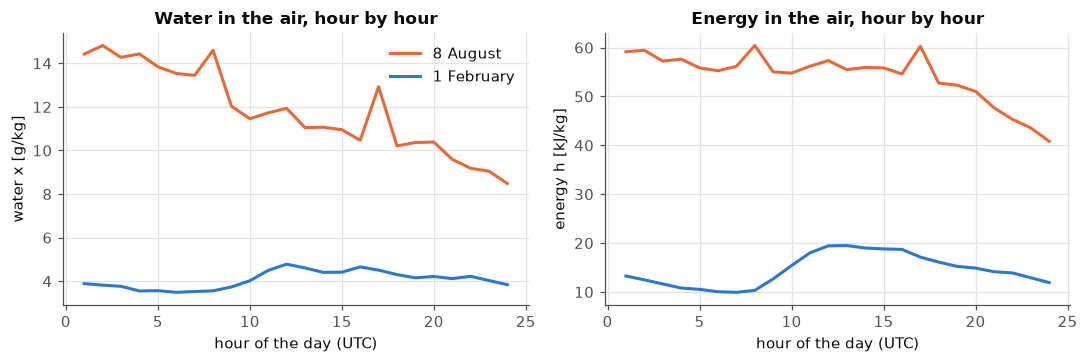

Summer: water 8.5-14.8 g/kg, energy 41-60 kJ/kg
Winter: water 3.5-4.8 g/kg, energy 10-19 kJ/kg


In [11]:
hours = np.arange(1, 25)
t_s = np.array([22.5, 21.8, 21, 21, 20.7, 20.9, 22, 23.3, 24.4, 25.6, 26.3, 26.9, 27.3, 27.7, 27.9, 27.9, 27.3, 26.7, 25.9, 24.6, 23.3, 22, 20.6, 19.3])
f_s = np.array([83, 89, 90, 91, 89, 86, 80, 80, 62, 55, 54, 53, 48, 47, 46, 44, 56, 46, 49, 53, 53, 55, 59, 60])
t_w = np.array([3.5, 2.9, 2.2, 1.9, 1.6, 1.3, 1.1, 1.4, 3.3, 5.3, 6.7, 7.4, 7.9, 7.9, 7.7, 7, 5.8, 5.3, 4.8, 4.3, 3.8, 3.3, 2.8, 2.3])
f_w = np.array([79, 81, 84, 81, 83, 83, 85, 84, 77, 72, 73, 74, 69, 66, 67, 74, 78, 77, 77, 81, 82, 87, 86, 85])

def day(t, phi):
    pv = phi / 100 * p_sat(t); x = humidity_ratio(pv)
    return 1000 * x, enthalpy(t, x)
xs, hs = day(t_s, f_s); xw, hw = day(t_w, f_w)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].plot(hours, xs, color=SUMMER, lw=2, label="8 August"); axs[0].plot(hours, xw, color=WINTER, lw=2, label="1 February")
axs[0].set_ylabel("water x [g/kg]"); axs[0].set_title("Water in the air, hour by hour")
axs[1].plot(hours, hs, color=SUMMER, lw=2); axs[1].plot(hours, hw, color=WINTER, lw=2)
axs[1].set_ylabel("energy h [kJ/kg]"); axs[1].set_title("Energy in the air, hour by hour")
for a in axs: a.set_xlabel("hour of the day (UTC)")
axs[0].legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Summer: water {xs.min():.1f}-{xs.max():.1f} g/kg, energy {hs.min():.0f}-{hs.max():.0f} kJ/kg")
print(f"Winter: water {xw.min():.1f}-{xw.max():.1f} g/kg, energy {hw.min():.0f}-{hw.max():.0f} kJ/kg")

**Reading it.** The summer air always carries much more water and energy than the winter air (roughly 3 to 4 times as much energy). That is why summer needs air-conditioning that **cools and dries**, while winter needs **heating** (and sometimes adding humidity).

## A7. Which curves move together?

All the graphs above show the **same few things**, and they are linked like the parts of a seesaw. Here is the rule-book, so you can read any graph:

| When this goes... | ...this happens | Why, in kid words |
|---|---|---|
| **Dew point goes down** | the water in the air ($x$) goes down too, and so does the water pressure $p_v$ and the hidden energy | The dew point **is** the water amount, just written as a temperature. Their curves look identical. |
| **Gap between air temperature and dew point gets bigger** | the air feels **drier** (relative humidity down), fewer drops | The further the air is from "sponge full", the drier it is |
| **Air gets warmer (water stays the same)** | the percentage (RH) goes **down**, but the grams of water and the dew point **don't change** | A warmer air has a bigger sponge, but it's the same water |
| **Air gets warmer** | each cubic metre weighs less | Warm air spreads out |
| **Water in the air goes up** | the air's energy $h$ goes up | Water carries hidden energy |
| **Temperature goes up** | the sponge $p_{sat}$ grows very quickly (a curve, not a straight line) | 7 times bigger from 0 °C to 30 °C |

**What really happened on the two days** (we measured it with a "friendship score" called correlation: +1 = always rise and fall together, −1 = perfect opposites, 0 = strangers):
- **Winter:** temperature and water rise and fall **together** (score 0.93), and the energy follows the temperature (0.99). The warm afternoon has a bigger sponge and fills it.
- **Summer:** temperature and water are almost **strangers** (−0.23). The air is most humid at night when it is coolest. The energy follows the **water** (0.84) more than the temperature (0.33).
- **Temperature and humidity percentage** are opposites on both days (−0.75 in summer, −0.89 in winter): afternoon warm → the percentage drops.

,Summer,Winter
t vs RH,-0.75,-0.89
t vs x,-0.23,0.93
tdp vs x,1.00,1.00
gap vs RH,-1.00,-1.00
x vs h,0.84,0.96
t vs h,0.33,0.99


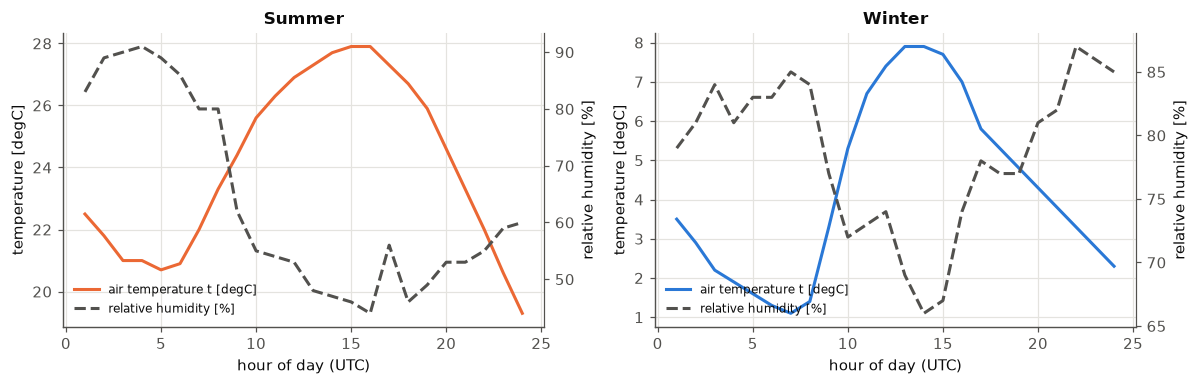

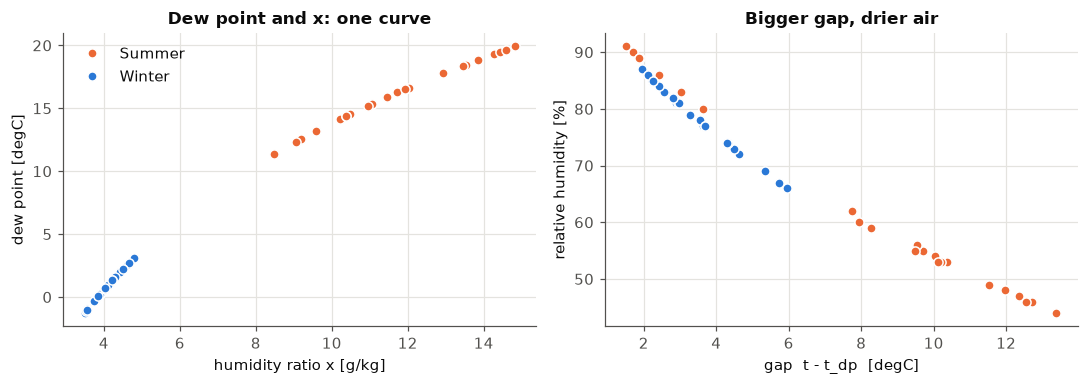

In [12]:
def day(t, phi):
    pv = phi / 100 * p_sat(t); x = 1000 * humidity_ratio(pv); tdp = t_sat(pv)
    return dict(t=t, RH=phi, x=x, tdp=tdp, gap=t - tdp, h=enthalpy(t, x / 1000))
days = {"Summer": (day(t_s, f_s), SUMMER), "Winter": (day(t_w, f_w), WINTER)}

# correlation: +1 = move together, -1 = mirror images, 0 = unrelated
pairs = [("t", "RH"), ("t", "x"), ("tdp", "x"), ("gap", "RH"), ("x", "h"), ("t", "h")]
display(pd.DataFrame({n: {f"{a} vs {b}": round(np.corrcoef(d[a], d[b])[0, 1], 2) for a, b in pairs} for n, (d, _) in days.items()}))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, (n, (d, col)) in zip(axs, days.items()):
    ax.plot(hours, d["t"], color=col, lw=2, label="air temperature t [degC]")
    ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("temperature [degC]"); ax.set_title(n)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.plot(hours, d["RH"], color=MUTED, lw=2, ls="--", label="relative humidity [%]"); ax2.set_ylabel("relative humidity [%]")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for n, (d, col) in days.items():
    axs[0].plot(d["x"], d["tdp"], "o", color=col, ms=6, mec="white", label=n)
    axs[1].plot(d["gap"], d["RH"], "o", color=col, ms=6, mec="white", label=n)
axs[0].set_xlabel("humidity ratio x [g/kg]"); axs[0].set_ylabel("dew point [degC]"); axs[0].set_title("Dew point and x: one curve"); axs[0].legend(frameon=False)
axs[1].set_xlabel("gap  t - t_dp  [degC]"); axs[1].set_ylabel("relative humidity [%]"); axs[1].set_title("Bigger gap, drier air")
plt.tight_layout(); plt.show()

**Reading it.**
- **Table:** numbers close to +1 or −1 mean the two curves are tightly linked. Dew point vs water amount is exactly 1.00 (they are the same information), and gap vs humidity percentage is exactly −1.00.
- **First pair of lines (solid = temperature, dashed = humidity percentage):** when one goes up the other goes down, like a seesaw.
- **Left dots:** all hours of both days lie on **one** curve: pick a dew point and you know the grams of water. Winter is bottom-left (cold, dry), summer top-right.
- **Right dots:** the further the air is from its dew point, the lower the percentage.

# Part B: Sheet 2, will a person feel comfortable?

## B0. The big idea: your body is a little campfire

Your body **makes heat** all the time (even asleep). The room **takes heat away**. Think of a **bathtub**: the tap is the heat you make, the drains are the ways the room steals it.

- Drains take **exactly** what the tap gives → water level steady → you feel **just right**.
- Drains take **less** → level rises → you feel **hot**.
- Drains take **more** → level sinks → you feel **cold**.

The number that says "how high is the water level" is the **PMV**. We then count how many people out of 100 would complain: the **PPD**.

## B1. Fancy words → simple words

| Fancy word | Simple meaning | Unit |
|---|---|---|
| **Metabolic rate** $M$ | How much heat your body makes (your campfire). Sitting still ≈ 1 met. Running makes much more. | met (1 met = 58.15 W/m² of skin) |
| **Clothing insulation** $I_{clo}$ | How warm your clothes are (a blanket around the bathtub). | clo (0.5 = light summer clothes, 1 = winter suit) |
| **Air temperature** $t_a$ | What a normal thermometer says. | °C |
| **Mean radiant temperature** $t_{mr}$ | How warm the **walls and windows** are. You feel a cold window even when the air is warm. | °C |
| **Operative temperature** $t_o$ | The **"feels-like" temperature**: a mix of air and wall temperature. | °C |
| **Air speed** $v$ | How strong the breeze is. Wind steals heat. | m/s |
| **Relative humidity** | How sticky the air is. Sticky air makes it harder to cool down by sweating. (This is Part A's sponge!) | % |
| **PMV** | The average **vote** of people from −3 (cold) to +3 (hot); 0 = just right. | no unit |
| **PPD** | The **% of people who are unhappy** (vote beyond ±1). | % |
| **Heat flux** | How much heat flows through each m² of skin. | W/m² |
| **Iteration** | Guess → improve the guess → repeat until the answer stops changing. | - |

## B2. Clothes are a guessing game

The clothes' outer surface has a temperature $t_{cl}$ that we don't know, but we need it to compute the heat that leaves through the clothes. And that heat itself depends on $t_{cl}$! A chicken-and-egg problem. The trick: **guess, improve, repeat** until the guess stops changing. The sheet asks us to count how many rounds it takes (we stop when the change is below 0.0015).

Outdoor: PMV = 1.767, PPD = 65.3 %, operative temperature = 30.25 degC, rounds of guessing = 8


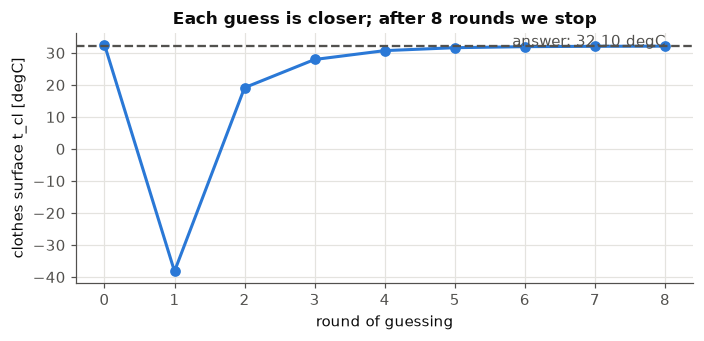

In [13]:
# outdoor summer case from the sheet: 30 degC air, 30.5 degC walls, 0.15 m/s, 60 % RH, 0.5 clo, 1.2 met
pmv, ppd, t_o, n, d = calculate_pmv_ppd(30, 30.5, details=True)
print(f"Outdoor: PMV = {pmv:.3f}, PPD = {ppd:.1f} %, operative temperature = {t_o:.2f} degC, rounds of guessing = {n}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(range(len(d['history'])), d['history'], "o-", color=BLUE, lw=2)
ax.axhline(d['t_cl'], color=MUTED, ls="--"); ax.text(len(d['history']) - 1, d['t_cl'] + 0.1, f"answer: {d['t_cl']:.2f} degC", ha="right", color=MUTED)
ax.set_xlabel("round of guessing"); ax.set_ylabel("clothes surface t_cl [degC]")
ax.set_title("Each guess is closer; after 8 rounds we stop")
plt.tight_layout(); plt.show()

**Reading it.** The first guess is a bit off, then each round gets closer, like finding a hidden toy by being told "warmer, warmer, ...". We stop when the answer moves less than 0.0015 (that is 0.15 °C). The sheet's answer is **8 rounds**.

## B3. Where does the heat go? (the 6 drains)

The body loses heat through six paths (all in W/m² of skin):

| Drain | In kid words |
|---|---|
| **RL1** | Water slowly seeping out through the skin |
| **RL2** | Sweating (only if you make more heat than when resting) |
| **RL3** | Water vapour you breathe out |
| **RL4** | Warm air you breathe out |
| **RL5** | Heat radiating from your clothes to the walls |
| **RL6** | Air carrying heat away from your clothes (breeze) |

What is left over is the **thermal load** $L = M - RL1 - \dots - RL6$. Then **PMV = (sensitivity) × L**. Positive means heat piles up (hot), negative means too much leaves (cold).

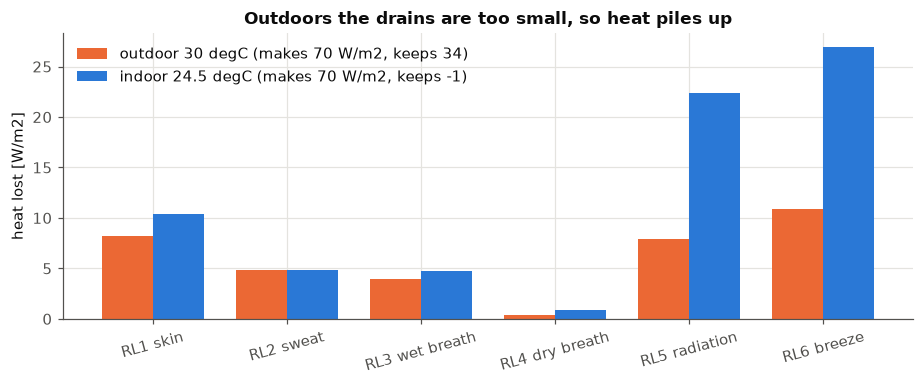

In [14]:
pm_in, pp_in, to_in, n_in, d_in = calculate_pmv_ppd(24.5, 25, details=True)
labels = ["RL1 skin", "RL2 sweat", "RL3 wet breath", "RL4 dry breath", "RL5 radiation", "RL6 breeze"]
out = [d[k] for k in ["RL1", "RL2", "RL3", "RL4", "RL5", "RL6"]]
ins = [d_in[k] for k in ["RL1", "RL2", "RL3", "RL4", "RL5", "RL6"]]
x = np.arange(6); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(x - w/2, out, w, color=ORANGE, label=f"outdoor 30 degC (makes {d['M']:.0f} W/m2, keeps {d['L']:.0f})")
ax.bar(x + w/2, ins, w, color=BLUE, label=f"indoor 24.5 degC (makes {d_in['M']:.0f} W/m2, keeps {d_in['L']:.0f})")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15); ax.set_ylabel("heat lost [W/m2]"); ax.legend(frameon=False)
ax.set_title("Outdoors the drains are too small, so heat piles up")
plt.tight_layout(); plt.show()

**Reading it.** The body makes about 70 W/m² in both cases. Indoors, the drains take away almost exactly that (little is left over → PMV ≈ 0). Outdoors, the radiation and breeze drains (RL5, RL6) nearly vanish because the air is as warm as your clothes, so about 30 W/m² piles up → you feel hot.

## B4. From heat left over to a vote (PMV) and complaints (PPD)

- **PMV** scale: −3 cold, −2 cool, −1 slightly cool, **0 neutral**, +1 slightly warm, +2 warm, +3 hot.
- **PPD** is the % unhappy. Even at a perfect PMV = 0, 5 % of people complain (we are all different!).
- A room is called **category I** (very good) when PMV is within ±0.2, category II within ±0.5, category III within ±0.7.

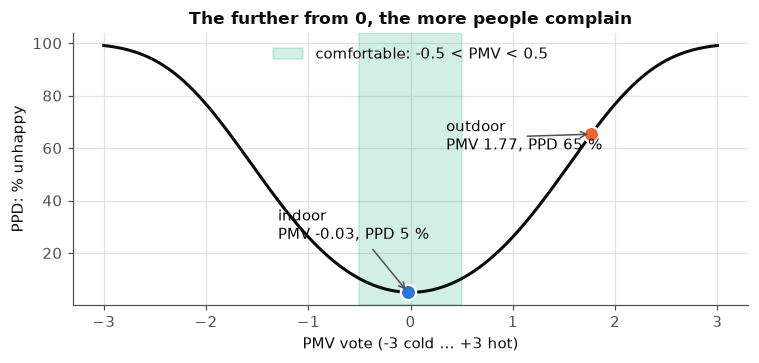

In [15]:
pv_ = np.linspace(-3, 3, 300)
ppd_ = 100 - 95 * np.exp(-0.03353 * pv_**4 - 0.2179 * pv_**2)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(-0.5, 0.5, color=AQUA, alpha=0.2, label="comfortable: -0.5 < PMV < 0.5")
ax.plot(pv_, ppd_, color=INK, lw=2)
ax.plot(pm_in, pp_in, "o", color=BLUE, ms=10, mec="white", mew=1.5); ax.annotate(f"indoor\nPMV {pm_in:.2f}, PPD {pp_in:.0f} %", (pm_in, pp_in), xytext=(-85, 35), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=MUTED))
ax.plot(pmv, ppd, "o", color=ORANGE, ms=10, mec="white", mew=1.5); ax.annotate(f"outdoor\nPMV {pmv:.2f}, PPD {ppd:.0f} %", (pmv, ppd), xytext=(-95, -10), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=MUTED))
ax.set_xlabel("PMV vote (-3 cold ... +3 hot)"); ax.set_ylabel("PPD: % unhappy"); ax.legend(frameon=False, loc="upper center")
ax.set_title("The further from 0, the more people complain")
plt.tight_layout(); plt.show()

**Reading it.** The curve is a bowl: lowest at 0 (5 %), rising fast on both sides. Outdoors (PMV 1.77) about **65 %** are unhappy; our indoor room (PMV −0.03) is at the bottom of the bowl, **5 %**.

## B5. Finding the right indoor temperature (the second half of the sheet)

We keep the same person (light clothes 0.5 clo, sitting 1.2 met, 60 % humidity, almost no breeze) and try air temperatures from 18 to 30 °C. In summer the walls are about 0.5 °C warmer than the air ($t_{mr} = t_a + 0.5$). We look for where **PMV stays between −0.5 and +0.5**.

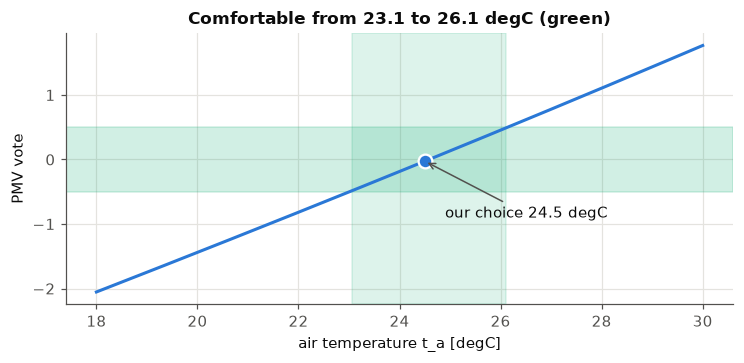

In [16]:
ta = np.linspace(18, 30, 241)
pm = np.array([calculate_pmv_ppd(t, t + 0.5)[0] for t in ta])
ok = ta[np.abs(pm) < 0.5]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axhspan(-0.5, 0.5, color=AQUA, alpha=0.2)
ax.plot(ta, pm, color=BLUE, lw=2)
ax.axvspan(ok.min(), ok.max(), color=AQUA, alpha=0.15)
ax.plot(24.5, pm_in, "o", color=BLUE, ms=9, mec="white", mew=1.5); ax.annotate("our choice 24.5 degC", (24.5, pm_in), xytext=(24.9, -0.9), arrowprops=dict(arrowstyle="->", color=MUTED))
ax.set_xlabel("air temperature t_a [degC]"); ax.set_ylabel("PMV vote")
ax.set_title(f"Comfortable from {ok.min():.1f} to {ok.max():.1f} degC (green)")
plt.tight_layout(); plt.show()

**Reading it.** The blue line climbs as the room gets warmer. The green zone is where people say "just right": about **23.0 to 26.1 °C**. We picked **24.5 °C** (air) / **25 °C** (walls): PMV = −0.03, PPD = 5 %, category I. Try clothes of 1.0 clo or activity of 2.0 met in the call above and watch the green zone slide down: **warmer clothes or more movement means you want a cooler room**.

## B6. Cheat-sheet: what to hand in

| Question | Sheet | Answer |
|---|---|---|
| Water pressure, grams of water, dew point, energy for summer / winter day | 1 | A3 table: 16.26 / 3.25 g/kg, 21.37 / −2.23 °C, 71.56 / 8.12 kJ/kg |
| Mass of air in the 6×4×3 m room | 1 | 84.14 kg (1.17 kg/m³) |
| PMV, PPD, $t_o$, rounds (outdoor 30 / 30.5 °C) | 2 | 1.767, 65.3 %, 30.25 °C, 8 |
| Indoor state with −0.5 < PMV < 0.5 | 2 | 24.5 / 25 °C → PMV −0.03, PPD 5.0 %, $t_o$ 24.75 °C |

**One sentence for each sheet:** *Sheet 1:* "Warm air has a big sponge, so summer air carries far more water and energy than winter air." *Sheet 2:* "Comfort is when the heat your body makes equals the heat the room takes away."

The detailed version of everything is in `lab-2-in-depth.ipynb`; the code version is `calculate_pmv_ppd.py`.